# 4.0 PCA diagnostico

**CRISP-DM fase 3 Â· Data Preparation Â· PCA diagnostico.**
Cuaderno satelite de `3.0_transformacion.ipynb`: profundiza en los componentes principales de las variables numericas escaladas, sin exportar una matriz reducida.
Muestra utilizada: `min(10000, n)` filas por version.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "refactor":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "MineriaProtect":
    for p in [ROOT] + list(ROOT.parents):
        if p.name == "MineriaProtect":
            ROOT = p
            break
sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.Transformacion.column_profile import profile_columns
from scripts.ScriptsCsv.Transformacion.config import VERSION_CON, VERSION_SIN, processed_path
from scripts.ScriptsCsv.Transformacion.date_features import add_date_ordinals, add_job_order, add_start_year
from scripts.ScriptsCsv.Transformacion.encoding import derive_skill_presence, ordinal_from_mapping
from scripts.ScriptsCsv.Transformacion.pca_diagnostic import components_for_threshold, run_pca, top_loadings
from scripts.ScriptsCsv.Transformacion.scaling import fit_transform_full

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
SAMPLE_SIZE = 10000


In [2]:
UNIV_ORDER = {"No reportado": 0, "Secondary school": 1, "Bachelor": 2, "Master": 3, "PhD": 4}
SCALING_PLAN = {
    "start_ord": "robust", "end_ord": "robust", "dur_q": "robust",
    "n_skills_essential": "robust", "n_skills_competence": "robust",
    "n_skills_knowledge": "robust", "n_skills_sin_tipo": "robust",
    "veces_ese_oficio": "robust", "start_year": "robust",
    "job_order": "robust", "univ_ord": "minmax",
}
def read_version(version):
    path = processed_path(version)
    df = pd.read_csv(path, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
    occupation = df["occupation_code"].fillna("").astype(str).str.strip()
    fusion = occupation.eq("") & df["matched_code"].astype(str).str.strip().ne("unknown")
    occupation.loc[fusion] = df.loc[fusion, "matched_code"].astype(str)
    df["occupation_code"] = occupation.replace("", pd.NA).fillna("unknown")
    df = add_date_ordinals(df, "start_date", "end_date")
    df = add_start_year(df)
    df = add_job_order(df, "resume_id", "start_ord")
    for col in ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = derive_skill_presence(df, ["skills", "knowledge", "sin_tipo"], ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"])
    df = ordinal_from_mapping(df, "university_level", UNIV_ORDER, "univ_ord")
    return df

df_con = read_version(VERSION_CON)
df_sin = read_version(VERSION_SIN)
work_con = df_con[df_con.n_skills_essential.notna()].copy().reset_index(drop=True)
work_sin = df_sin[df_sin.n_skills_essential.notna()].copy().reset_index(drop=True)
print("Universo con/sin:", work_con.shape, work_sin.shape)


Universo con/sin: (348263, 32) (348263, 32)


In [3]:
sample_n = lambda n, size: min(size, len(n))
sample_con = work_con[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_con, SAMPLE_SIZE), random_state=RANDOM_SEED)
sample_sin = work_sin[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_sin, SAMPLE_SIZE), random_state=RANDOM_SEED)
_, scaled_con = fit_transform_full(sample_con, SCALING_PLAN)
_, scaled_sin = fit_transform_full(sample_sin, SCALING_PLAN)

var_con, load_con, _ = run_pca(scaled_con, n_components=10)
var_sin, load_sin, _ = run_pca(scaled_sin, n_components=10)
print("Componentes 80/90 (con):", components_for_threshold(var_con, 0.80), components_for_threshold(var_con, 0.90))
print("Componentes 80/90 (sin):", components_for_threshold(var_sin, 0.80), components_for_threshold(var_sin, 0.90))
display(var_con)
display(var_sin)


Componentes 80/90 (con): 4 5
Componentes 80/90 (sin): 3 5


,component,explained_variance_ratio,cumulative_variance
0,PC1,3.221460e-01,0.322146
1,PC2,2.202423e-01,0.542388
2,PC3,2.098219e-01,0.752210
3,PC4,1.246608e-01,0.876871
4,PC5,6.455746e-02,0.941428
5,PC6,5.298559e-02,0.994414
6,PC7,4.531463e-03,0.998945
7,PC8,1.024852e-03,0.999970
8,PC9,2.973074e-05,1.000000
9,PC10,1.831125e-17,1.000000


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.390924,0.390924
1,PC2,0.263766,0.654690
2,PC3,0.146564,0.801254
3,PC4,0.088430,0.889683
4,PC5,0.064472,0.954156
5,PC6,0.038627,0.992783
6,PC7,0.005466,0.998249
7,PC8,0.001250,0.999499
8,PC9,0.000465,0.999964
9,PC10,0.000036,1.000000



Top loadings PC1 (con):


,abs_loading,signed_loading
dur_q_rob,0.839951,0.839951
start_ord_rob,0.340614,-0.340614
start_year_rob,0.339264,-0.339264
job_order_rob,0.173959,-0.173959
veces_ese_oficio_rob,0.113595,-0.113595
end_ord_rob,0.097505,-0.097505



Top loadings PC1 (sin):


,abs_loading,signed_loading
dur_q_rob,0.850352,0.850352
start_ord_rob,0.343276,-0.343276
start_year_rob,0.341907,-0.341907
job_order_rob,0.168233,-0.168233
end_ord_rob,0.096905,-0.096905
veces_ese_oficio_rob,0.054339,-0.054339



Top loadings PC2 (con):


,abs_loading,signed_loading
end_ord_rob,0.462366,0.462366
n_skills_essential_rob,0.438038,0.438038
n_skills_competence_rob,0.415523,0.415523
dur_q_rob,0.409722,0.409722
start_year_rob,0.272973,0.272973
start_ord_rob,0.272956,0.272956


... (2 outputs left out)


Top loadings PC3 (con):


,abs_loading,signed_loading
n_skills_essential_rob,0.493459,0.493459
n_skills_competence_rob,0.462880,0.462880
end_ord_rob,0.436649,-0.436649
start_ord_rob,0.308978,-0.308978
start_year_rob,0.308747,-0.308747
n_skills_knowledge_rob,0.264614,0.264614



Top loadings PC3 (sin):


,abs_loading,signed_loading
n_skills_essential_rob,0.668064,0.668064
n_skills_competence_rob,0.661356,0.661356
n_skills_knowledge_rob,0.282371,0.282371
veces_ese_oficio_rob,0.155705,0.155705
job_order_rob,0.074510,0.074510
start_ord_rob,0.044808,-0.044808


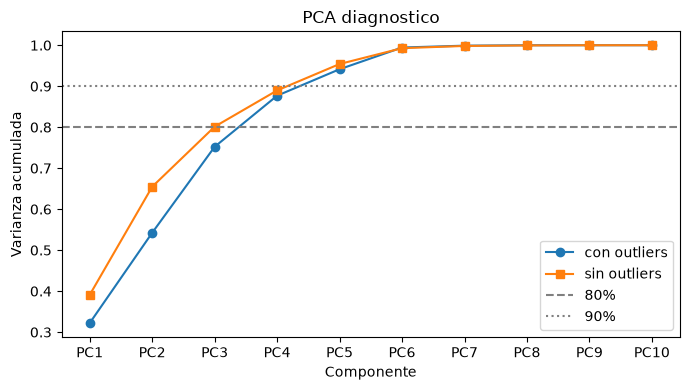

In [4]:
for pc in ["PC1", "PC2", "PC3"]:
    print(f"\nTop loadings {pc} (con):")
    display(top_loadings(load_con, pc, n=6))
    print(f"\nTop loadings {pc} (sin):")
    display(top_loadings(load_sin, pc, n=6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(var_con["component"], var_con["cumulative_variance"], marker="o", label="con outliers")
ax.plot(var_sin["component"], var_sin["cumulative_variance"], marker="s", label="sin outliers")
ax.axhline(0.8, linestyle="--", color="gray", label="80%")
ax.axhline(0.9, linestyle=":", color="gray", label="90%")
ax.set_ylabel("Varianza acumulada")
ax.set_xlabel("Componente")
ax.set_title("PCA diagnostico")
ax.legend()
plt.tight_layout()
plt.show()


## Lectura del diagnostico

El PCA se usa solo como diagnostico. Si `start_ord`, `end_ord` y `dur_q` dominan los primeros componentes, eso indica redundancia lineal (dur_q = end_ord - start_ord + 1), no un enriquecimiento util. Si las columnas de skills pesan por separado, hay informacion propia de complejidad del oficio. Ganar varianza acumulada rapida no significa necesariamente que las variables sean intercambiables para el negocio: los loadings deben leerse junto con la pregunta de transiciones.
